In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ashfakyeafi/road-vehicle-images-dataset")

print("Path to dataset files:", path)

C:\Users\Youcode\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\Youcode\.cache\kagglehub\datasets\ashfakyeafi\road-vehicle-images-dataset\versions\2


In [3]:
from pathlib import Path

path_dataset = Path(path) / "trafic_data"

In [4]:

for dir in path_dataset.iterdir():
    print(dir.name)

data_1.yaml
train
valid


In [5]:
train_ds = path_dataset / "train"
validation_ds = path_dataset / "valid"

In [6]:
for i in train_ds.iterdir():
    print(i.name)

images
labels
labels.cache


training images len :  2704 labels images len :  2704
validation len :  300 labels images len :  300


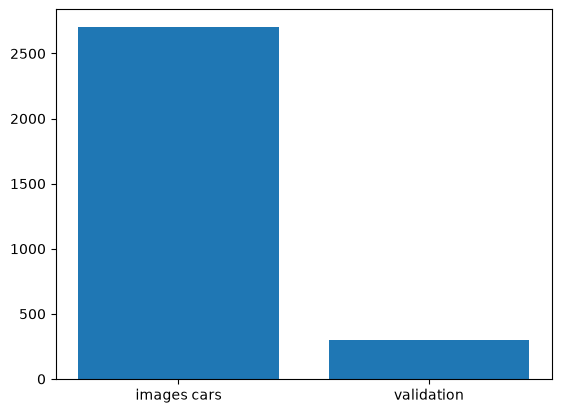

In [7]:
import matplotlib.pyplot as plt

training_images = train_ds / "images"
training_lebels = train_ds / "labels"
validation_images = validation_ds / "images"
validation_lebels = validation_ds / "labels"
print("training images len : " , len(list(training_images.glob("*"))) , "labels images len : " , len(list(training_lebels.glob("*"))))
print("validation len : " , len(list(validation_images.glob("*"))) , "labels images len : " , len(list(validation_lebels.glob("*"))))



plt.bar(["images cars" , "validation"] , [len(list(training_images.glob("*"))) , len(list(validation_images.glob("*")))] , )
plt.show()

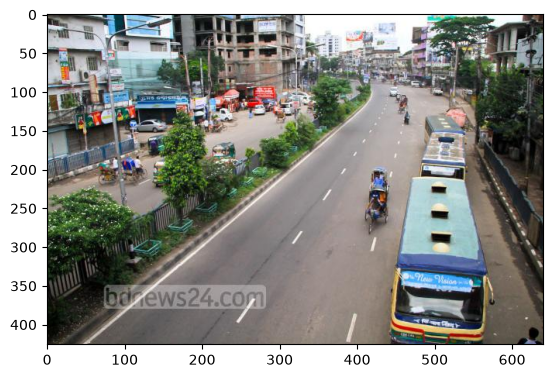

In [8]:

image_path = next(training_images.iterdir())

img = plt.imread(image_path)
plt.imshow(img)
plt.show()

In [9]:
img.shape

(426, 640, 3)

In [10]:
from pathlib import Path


labels_path = path_dataset / "train" / "labels"

label_files = list(labels_path.glob("*.txt"))

print("Nombre de fichiers labels :", len(label_files))

# Afficher le premier label
# label_file = label_files[0]

for label_file in label_files:
    content = label_file.read_text().strip()

    if content:
        print("Fichier :", label_file.name)
        print(content)
        break

Nombre de fichiers labels : 2704
Fichier : 02_jpg.rf.65a084066fc353cd023eb5c953f40efe.txt
17 0.9546875 0.6892523364485982 0.0859375 0.11682242990654206
19 0.721875 0.5607476635514018 0.0953125 0.11448598130841121
17 0.3671875 0.6635514018691588 0.05625 0.10514018691588785
10 0.2828125 0.48130841121495327 0.0171875 0.037383177570093455
10 0.4015625 0.5327102803738317 0.01875 0.04906542056074766
10 0.675 0.4766355140186916 0.0234375 0.0397196261682243
10 0.696875 0.4602803738317757 0.0171875 0.030373831775700934
10 0.3390625 0.3317757009345794 0.0078125 0.014018691588785047
10 0.4015625 0.308411214953271 0.00625 0.009345794392523364
10 0.478125 0.3317757009345794 0.0078125 0.016355140186915886
16 0.2984375 0.3107476635514019 0.0140625 0.016355140186915886
11 0.315625 0.308411214953271 0.0140625 0.02336448598130841
4 0.2828125 0.29906542056074764 0.01875 0.037383177570093455
4 0.2796875 0.2733644859813084 0.0171875 0.014018691588785047
17 0.3296875 0.4369158878504673 0.021875 0.0467289719

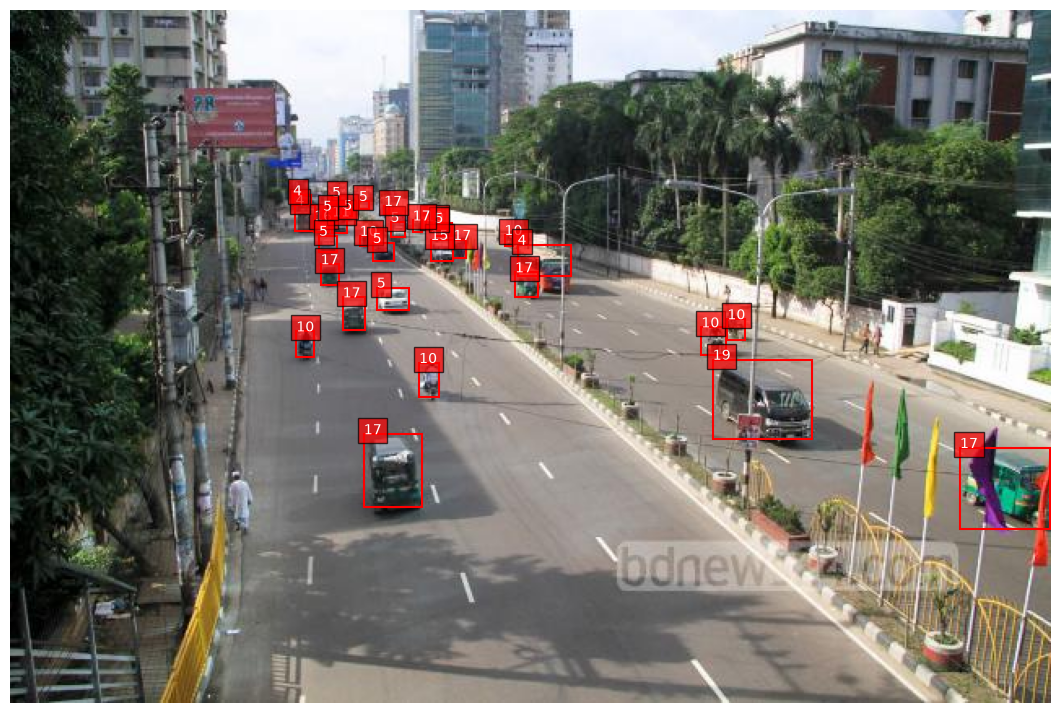

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

images_path = path_dataset / "train" / "images"
labels_path = path_dataset / "train" / "labels"

label_file = labels_path / "02_jpg.rf.65a084066fc353cd023eb5c953f40efe.txt"

image_file = images_path / (label_file.stem + ".jpg")

image = Image.open(image_file).convert("RGB")
width, height = image.size

fig, ax = plt.subplots(figsize=(14, 9))
ax.imshow(image)

for line in label_file.read_text().splitlines():
    values = line.split()

    class_id = int(values[0])
    x_center, y_center, box_width, box_height = map(float, values[1:5])

    x_center *= width
    y_center *= height
    box_width *= width
    box_height *= height

    x_min = x_center - box_width / 2
    y_min = y_center - box_height / 2

    rectangle = patches.Rectangle(
        (x_min, y_min),
        box_width,
        box_height,
        linewidth=1.5,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rectangle)
    ax.text(x_min, y_min, str(class_id), color="white",
            bbox=dict(facecolor="red", alpha=0.7))

ax.axis("off")
plt.show()

In [12]:
from pathlib import Path

for file in Path(path).rglob("*.yaml"):
    print(file)

C:\Users\Youcode\.cache\kagglehub\datasets\ashfakyeafi\road-vehicle-images-dataset\versions\2\trafic_data\data_1.yaml


In [14]:
yaml_file = Path("data_1.yaml")
print(yaml_file.read_text())

FileNotFoundError: [Errno 2] No such file or directory: 'data_1.yaml'